# Classical Image Processing to Deep-Learning Object Detection

**Topics covered:** Morphological Operations, Bitwise Operations, Image Histograms,
Face Detection (YuNet), Object Detection (YOLOv8), Integrated Real-Time Pipeline

## Task 1: Environment Setup, Image I/O & Morphological Operations

### 1.1 Environment Setup & Image Loading

In [5]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
print("OpenCV version:", cv2.__version__)

OpenCV version: 5.0.0


In [6]:
def show(img, title="", cmap=None):
    if img.ndim == 3:
        img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
        plt.imshow(img)
    else:
        plt.imshow(img, cmap="gray" if cmap is None else cmap)
    plt.title(title)
    plt.axis("off")

In [7]:
IMG_DIR = r"C:\Users\91879\OneDrive\Desktop\RNW\Deep learning\PR 3\data\images\\"
PLOTS_DIR = r"C:\Users\91879\OneDrive\Desktop\RNW\Deep learning\PR 3\plots\\"

gray_img = cv2.imread(IMG_DIR + "baboon.jpg", cv2.IMREAD_GRAYSCALE)
colour_img = cv2.imread(IMG_DIR + "lena.jpg", cv2.IMREAD_COLOR)

print("Grayscale image -> shape:", gray_img.shape, " dtype:", gray_img.dtype)
print("Colour image    -> shape:", colour_img.shape, " dtype:", colour_img.dtype)

Grayscale image -> shape: (512, 512)  dtype: uint8
Colour image    -> shape: (512, 512, 3)  dtype: uint8


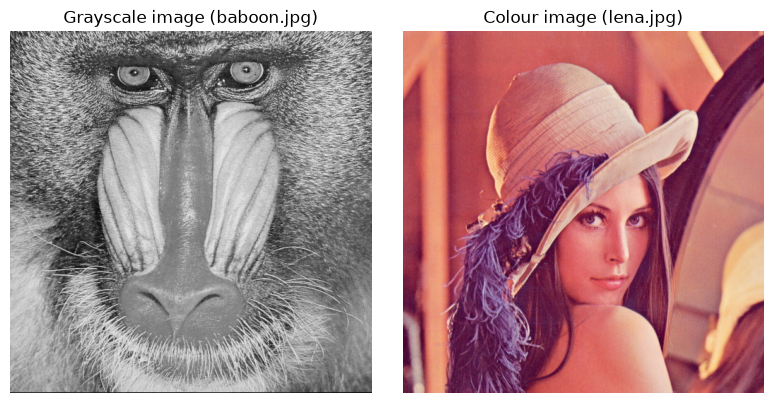

In [8]:
plt.figure(figsize=(8, 4))
plt.subplot(1, 2, 1)
show(gray_img, "Grayscale image (baboon.jpg)")
plt.subplot(1, 2, 2)
show(colour_img, "Colour image (lena.jpg)")
plt.tight_layout()
plt.show()

**Observation:** The grayscale image has a 2D shape (height, width) since it has a
single channel, while the colour image has a 3D shape (height, width, 3) for the B, G, R
channels. Both images are of dtype `uint8`, meaning each pixel value ranges from 0 to 255.

### 1.2 Binarize a Test Image

In [11]:
morph_source = cv2.imread(IMG_DIR + "baboon.jpg", cv2.IMREAD_COLOR)
morph_gray = cv2.cvtColor(morph_source, cv2.COLOR_BGR2GRAY)
_, morph_binary = cv2.threshold(morph_gray, 127, 255, cv2.THRESH_BINARY)

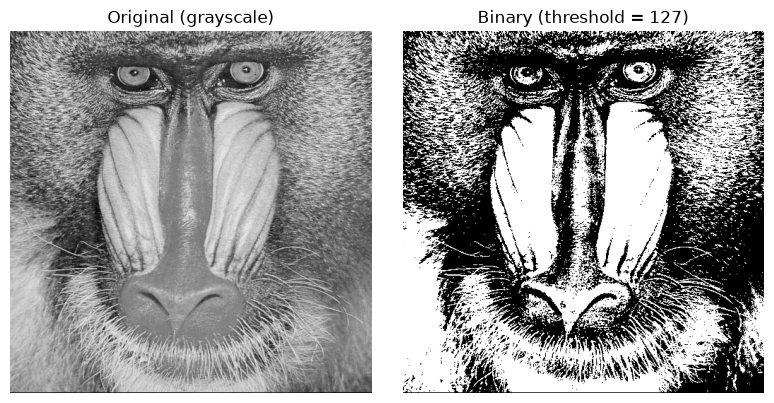

In [12]:
plt.figure(figsize=(8, 4))
plt.subplot(1, 2, 1)
show(morph_gray, "Original (grayscale)")
plt.subplot(1, 2, 2)
show(morph_binary, "Binary (threshold = 127)")
plt.tight_layout()
plt.show()

### 1.3 Apply the Four Morphological Operations

In [14]:
kernel = np.ones((5, 5), np.uint8)

erosion = cv2.erode(morph_binary, kernel, iterations=1)
dilation = cv2.dilate(morph_binary, kernel, iterations=1)
opening = cv2.morphologyEx(morph_binary, cv2.MORPH_OPEN, kernel)
closing = cv2.morphologyEx(morph_binary, cv2.MORPH_CLOSE, kernel)

images = [morph_binary, erosion, dilation, opening, closing]
titles = ["Original (binary)", "Erosion", "Dilation", "Opening", "Closing"]

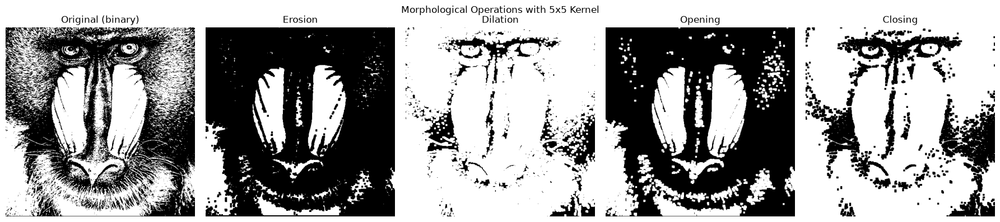

Saved: plots/morphology_grid.png


In [15]:
plt.figure(figsize=(18, 4))
for i in range(5):
    plt.subplot(1, 5, i + 1)
    show(images[i], titles[i])
plt.suptitle("Morphological Operations with 5x5 Kernel")
plt.tight_layout()
plt.savefig(PLOTS_DIR + "morphology_grid.png", dpi=150, bbox_inches="tight")
plt.show()
print("Saved: plots/morphology_grid.png")

### 1.4 Kernel Shape & Size Comparison

In [17]:
np.random.seed(42)
clean = np.zeros((300, 300), np.uint8)
cv2.circle(clean, (150, 150), 90, 255, -1)

noisy = clean.copy()
noise_mask = np.random.random(noisy.shape)
noisy[noise_mask < 0.02] = 255   # salt
noisy[noise_mask > 0.98] = 0     # pepper

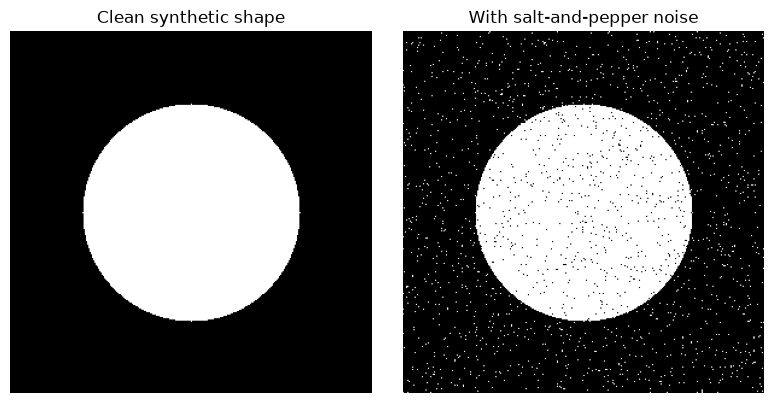

In [18]:
plt.figure(figsize=(8, 4))
plt.subplot(1, 2, 1)
show(clean, "Clean synthetic shape")
plt.subplot(1, 2, 2)
show(noisy, "With salt-and-pepper noise")
plt.tight_layout()
plt.show()

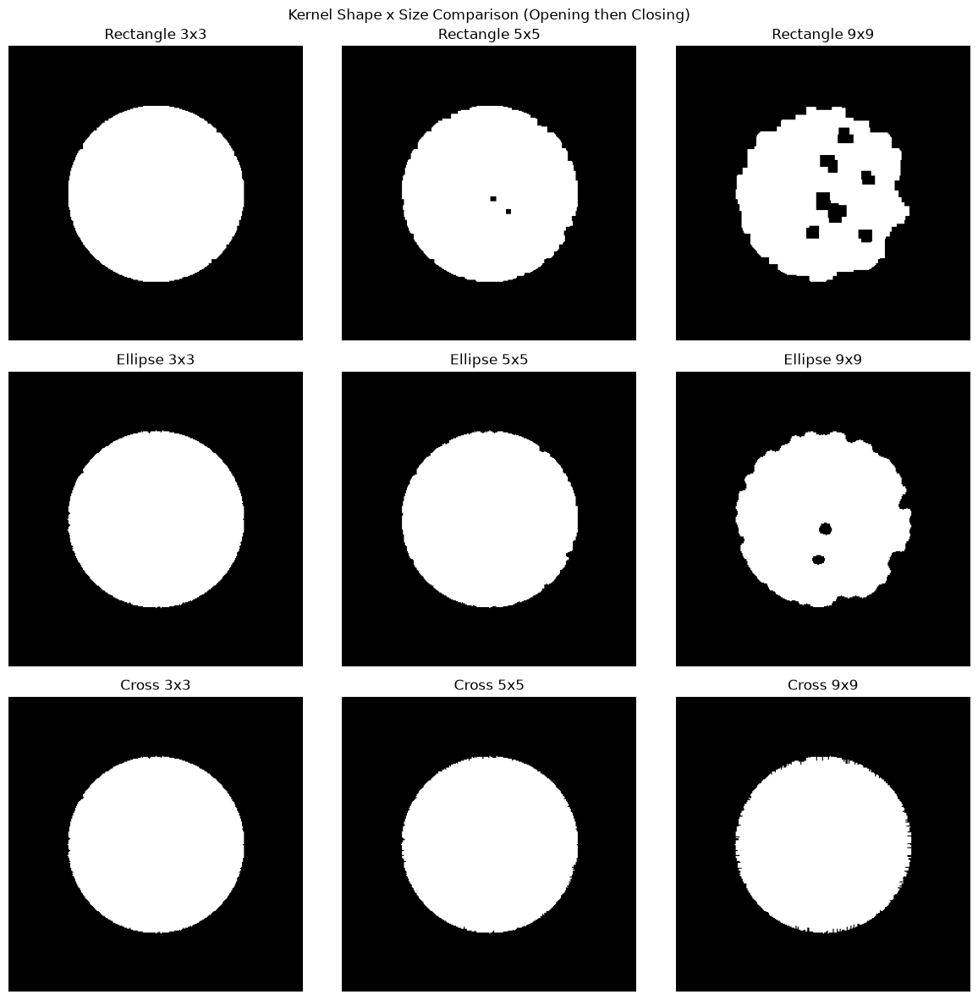

In [19]:
shapes = {"Rectangle": cv2.MORPH_RECT, "Ellipse": cv2.MORPH_ELLIPSE, "Cross": cv2.MORPH_CROSS}
sizes = [3, 5, 9]

plt.figure(figsize=(12, 12))
plot_index = 1
for shape_name, shape_flag in shapes.items():
    for size in sizes:
        se = cv2.getStructuringElement(shape_flag, (size, size))
        cleaned = cv2.morphologyEx(noisy, cv2.MORPH_OPEN, se)
        cleaned = cv2.morphologyEx(cleaned, cv2.MORPH_CLOSE, se)
        plt.subplot(3, 3, plot_index)
        show(cleaned, f"{shape_name} {size}x{size}")
        plot_index += 1

plt.suptitle("Kernel Shape x Size Comparison (Opening then Closing)")
plt.tight_layout()
plt.show()

In [20]:
print(f"{'Shape':10} {'Size':6} {'Residual Noise':16} {'Shape Erosion':14}")
for shape_name, shape_flag in shapes.items():
    for size in sizes:
        se = cv2.getStructuringElement(shape_flag, (size, size))
        cleaned = cv2.morphologyEx(noisy, cv2.MORPH_OPEN, se)
        cleaned = cv2.morphologyEx(cleaned, cv2.MORPH_CLOSE, se)
        residual_noise = int(np.sum((cleaned == 255) & (clean == 0)))
        shape_erosion = int(np.sum((cleaned == 0) & (clean == 255)))
        print(f"{shape_name:10} {size}x{size:<4} {residual_noise:<16} {shape_erosion:<14}")

Shape      Size   Residual Noise   Shape Erosion 
Rectangle  3x3    1                60            
Rectangle  5x5    1                390           
Rectangle  9x9    0                3881          
Ellipse    3x3    7                38            
Ellipse    5x5    1                180           
Ellipse    9x9    1                1546          
Cross      3x3    7                38            
Cross      5x5    7                97            
Cross      9x9    5                313           


**Observation:** The measured numbers above show two competing effects. At **3x3 and
5x5**, every kernel shape already removes almost all the salt-and-pepper noise (residual
noise of only a handful of pixels), while damage to the circle's true outline (shape
erosion) stays fairly small. At **9x9**, the rectangle and ellipse kernels remove the last
few stray noise pixels but cause far more damage to the outline (thousands of wrongly
removed pixels), because their fuller structuring elements erode much more aggressively.
The cross kernel causes the least outline damage even at 9x9, since it only touches 4
neighbouring pixels, but for the same reason it is slightly less thorough at clearing every
last noise speck. Overall, a **small kernel (3x3 or 5x5)** gives the best trade-off here: it
already clears nearly all the noise, and going up to 9x9 mostly just damages the object
outline without meaningfully improving noise removal.

### 1.5 WHY Morphology Works

**Erosion** acts like a local **minimum filter**: for every pixel, it looks at its
neighbourhood (defined by the kernel) and keeps the *minimum* value found there. On a binary
image this means a white pixel survives only if *all* pixels under the kernel are white.
The effect is that white regions shrink and small bright noise specks disappear entirely,
because a single isolated white pixel has no white neighbours to support it.

**Dilation** is the opposite: a local **maximum filter**. A pixel becomes white if *any*
pixel under the kernel is white. This grows white regions and fills small dark gaps or
holes inside them.

**Opening** = erosion followed by dilation. The erosion step wipes out small noise specks
(since they cannot survive being shrunk), and the following dilation step grows the
remaining (larger) regions back close to their original size. Net effect: small noise is
removed while the overall shape and size of real objects is preserved.

**Closing** = dilation followed by erosion. The dilation step first fills in small holes
and gaps inside/between white regions, and the following erosion shrinks everything back
down, so small holes stay filled while the outer boundary returns close to its original
size.

**Practical scenarios:**
- **Opening** is useful when a camera frame has small bright specks of sensor noise before
  running a face or object detector — it removes those specks without inflating the objects
  the detector actually needs to see.
- **Closing** is useful when a segmented object (for example a hand or a person silhouette
  from background subtraction) has small holes or gaps from partial occlusion or shadows —
  closing fills those gaps so the downstream detector sees one solid connected region
  instead of several broken pieces.

## Task 2: Bitwise Operations & Image Histograms

### 2.1 Bitwise AND / OR / XOR / NOT

In [25]:
mask1 = np.zeros((300, 300), np.uint8)
cv2.circle(mask1, (150, 150), 100, 255, -1)

mask2 = np.zeros((300, 300), np.uint8)
cv2.rectangle(mask2, (60, 60), (240, 240), 255, -1)

bit_and = cv2.bitwise_and(mask1, mask2)
bit_or = cv2.bitwise_or(mask1, mask2)
bit_xor = cv2.bitwise_xor(mask1, mask2)
bit_not = cv2.bitwise_not(mask1)

images = [mask1, mask2, bit_and, bit_or, bit_xor, bit_not]
titles = ["Mask 1 (circle)", "Mask 2 (rectangle)", "AND", "OR", "XOR", "NOT (of mask 1)"]

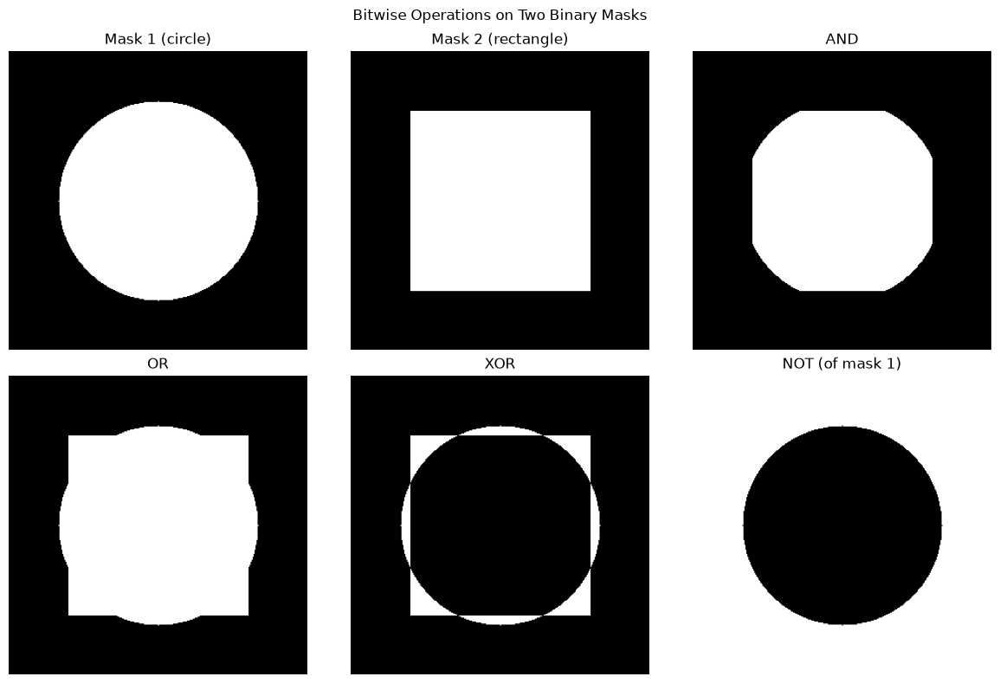

In [26]:
plt.figure(figsize=(12, 8))
for i in range(6):
    plt.subplot(2, 3, i + 1)
    show(images[i], titles[i])
plt.suptitle("Bitwise Operations on Two Binary Masks")
plt.tight_layout()
plt.show()

**Observation:** AND keeps only the region where both masks overlap. OR keeps
everything covered by either mask. XOR keeps only the parts that belong to exactly one mask
(the overlap is removed). NOT simply inverts mask 1, turning white to black and black to
white.

### 2.2 Applied Use Case: Masked Overlay

In [29]:
photo = cv2.imread(IMG_DIR + "lena.jpg", cv2.IMREAD_COLOR)
h, w = photo.shape[:2]

roi_mask = np.zeros((h, w), np.uint8)
cv2.circle(roi_mask, (w // 2, h // 2), min(h, w) // 3, 255, -1)

extracted = cv2.bitwise_and(photo, photo, mask=roi_mask)

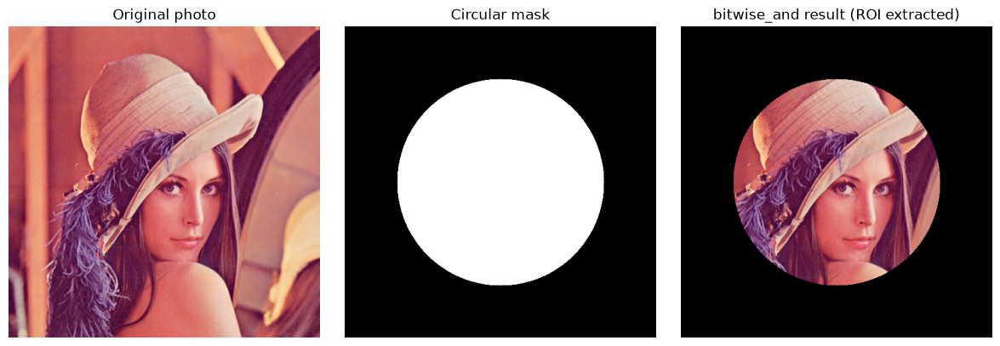

In [30]:
plt.figure(figsize=(12, 4))
plt.subplot(1, 3, 1)
show(photo, "Original photo")
plt.subplot(1, 3, 2)
show(roi_mask, "Circular mask")
plt.subplot(1, 3, 3)
show(extracted, "bitwise_and result (ROI extracted)")
plt.tight_layout()
plt.show()

In [31]:
background = cv2.imread(IMG_DIR + "fruits.jpg", cv2.IMREAD_COLOR)
logo = cv2.imread(IMG_DIR + "opencv-logo.png", cv2.IMREAD_COLOR)
logo = cv2.resize(logo, (120, 120))

bh, bw = background.shape[:2]
lh, lw = logo.shape[:2]
x_off, y_off = bw - lw - 10, bh - lh - 10

roi = background[y_off:y_off + lh, x_off:x_off + lw].copy()
combined_roi = cv2.bitwise_or(roi, logo)

watermarked = background.copy()
watermarked[y_off:y_off + lh, x_off:x_off + lw] = combined_roi

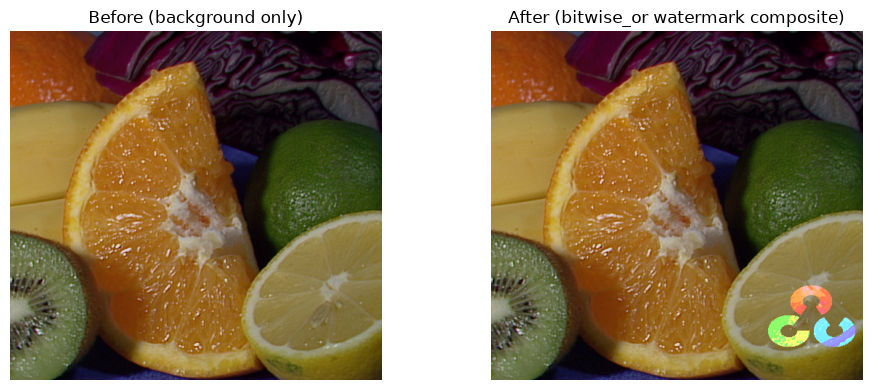

In [32]:
plt.figure(figsize=(10, 4))
plt.subplot(1, 2, 1)
show(background, "Before (background only)")
plt.subplot(1, 2, 2)
show(watermarked, "After (bitwise_or watermark composite)")
plt.tight_layout()
plt.show()

**Observation:** `bitwise_and` with a mask keeps only the pixels of the photo that fall
inside the white region of the mask, turning everything outside black — this is how a
region of interest is extracted. `bitwise_or` combines the bright pixels of the logo with
the background region, compositing the watermark onto the photo (this simple approach works
best when the logo has a mostly black background so the OR does not wash out the
background).

### 2.3 Grayscale & Per-Channel Colour Histograms

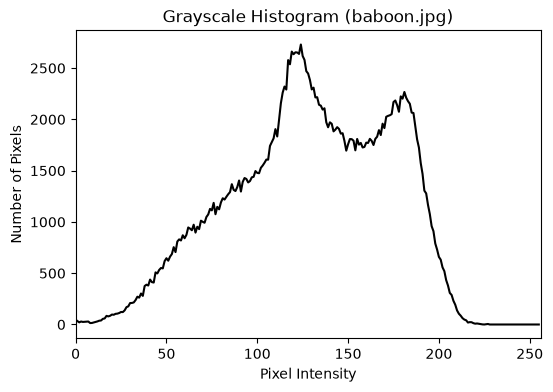

In [35]:
hist_gray_img = cv2.imread(IMG_DIR + "baboon.jpg", cv2.IMREAD_GRAYSCALE)
gray_hist = cv2.calcHist([hist_gray_img], [0], None, [256], [0, 256])

plt.figure(figsize=(6, 4))
plt.plot(gray_hist, color="black")
plt.title("Grayscale Histogram (baboon.jpg)")
plt.xlabel("Pixel Intensity")
plt.ylabel("Number of Pixels")
plt.xlim([0, 256])
plt.show()

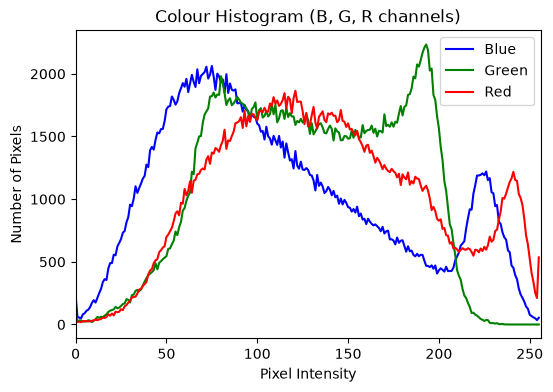

In [36]:
hist_colour_img = cv2.imread(IMG_DIR + "baboon.jpg", cv2.IMREAD_COLOR)
colours = ("b", "g", "r")
channel_names = ("Blue", "Green", "Red")

plt.figure(figsize=(6, 4))
for i, col in enumerate(colours):
    channel_hist = cv2.calcHist([hist_colour_img], [i], None, [256], [0, 256])
    plt.plot(channel_hist, color=col, label=channel_names[i])
plt.title("Colour Histogram (B, G, R channels)")
plt.xlabel("Pixel Intensity")
plt.ylabel("Number of Pixels")
plt.xlim([0, 256])
plt.legend()
plt.show()

### 2.4 Brightness & Contrast Adjustment

In [38]:
bc_source = cv2.imread(IMG_DIR + "lena.jpg", cv2.IMREAD_COLOR)
bc_gray = cv2.cvtColor(bc_source, cv2.COLOR_BGR2GRAY)

brighter = cv2.convertScaleAbs(bc_source, alpha=1.5, beta=30)
darker = cv2.convertScaleAbs(bc_source, alpha=0.7, beta=-30)

brighter_gray = cv2.cvtColor(brighter, cv2.COLOR_BGR2GRAY)
darker_gray = cv2.cvtColor(darker, cv2.COLOR_BGR2GRAY)

versions = [bc_source, brighter, darker]
version_titles = ["Original", "Brighter/Higher Contrast\n(alpha=1.5, beta=30)",
                   "Darker/Lower Contrast\n(alpha=0.7, beta=-30)"]
gray_versions = [bc_gray, brighter_gray, darker_gray]

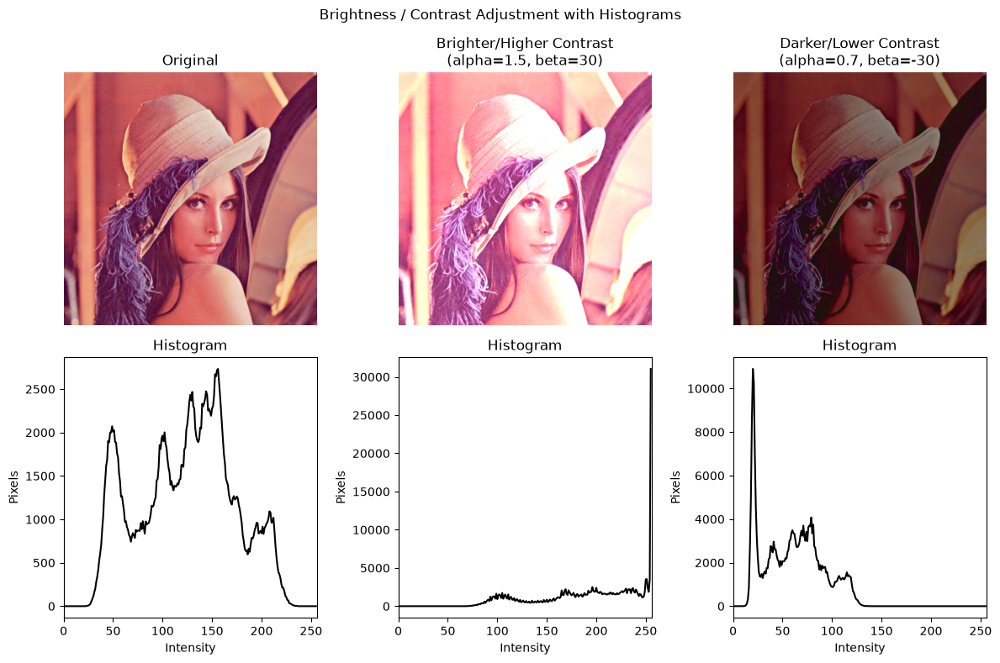

Saved: plots/histogram_comparison.png


In [39]:
plt.figure(figsize=(12, 8))
for i in range(3):
    plt.subplot(2, 3, i + 1)
    show(versions[i], version_titles[i])

    plt.subplot(2, 3, i + 4)
    hist = cv2.calcHist([gray_versions[i]], [0], None, [256], [0, 256])
    plt.plot(hist, color="black")
    plt.title("Histogram")
    plt.xlabel("Intensity")
    plt.ylabel("Pixels")
    plt.xlim([0, 256])

plt.suptitle("Brightness / Contrast Adjustment with Histograms")
plt.tight_layout()
plt.savefig(PLOTS_DIR + "histogram_comparison.png", dpi=150, bbox_inches="tight")
plt.show()
print("Saved: plots/histogram_comparison.png")

**Observation:** The brighter/higher-contrast version shifts and stretches the
histogram to the right and wider, with some pixels clipping at 255 (a spike at the right
edge). The darker/lower-contrast version shifts and compresses the histogram to the left
and narrower, with pixels bunching up near the low end.

### 2.5 WHY alpha/beta and Histograms Matter

`cv2.convertScaleAbs` applies the linear transform:

**new_pixel = alpha * pixel + beta**

- **alpha** controls **contrast**. Values above 1 stretch the histogram outward (dark pixels
  get darker, bright pixels get brighter, increasing the spread), while values below 1
  compress the histogram inward (all pixel values move closer together, reducing spread).
- **beta** controls **brightness**. It simply adds a constant offset to every pixel, which
  shifts the entire histogram left (negative beta, darker image) or right (positive beta,
  brighter image) without changing its shape.

A **narrow histogram** (all pixel values clustered in a small range) indicates a low-contrast,
washed-out image — there is not much difference between the darkest and brightest areas.
A histogram that is **clipped/spiked at 0 or 255** indicates under-exposure (too many pixels
pushed to pure black) or over-exposure (too many pixels pushed to pure white), meaning detail
has been lost in that region.

This diagnostic view is useful before running the face or object detectors in later tasks:
if a captured frame's histogram is narrow or heavily clipped, a quick brightness/contrast
correction can improve detection accuracy, since both YuNet and YOLO were trained mostly on
well-exposed images and perform worse on very dark or very washed-out frames.

## Task 3: Face Detection with YuNet (OpenCV 5.0)

**Objective:** Load OpenCV 5.0's YuNet face detector and use it to detect faces, landmarks,
and confidence scores on static images and a live webcam feed.

**Expected output:** Bounding boxes, 5-point landmarks, and confidence scores drawn on
static test images; a live webcam demo with reported FPS; a score-threshold comparison; and
a face-blurring privacy demo.

**Note on the model file:** `face_detection_yunet_2023mar.onnx` must be present at
`data/models/face_detection_yunet_2023mar.onnx`. In this build environment the file could
not be downloaded automatically because the official OpenCV Zoo repository stores it via
Git LFS / Xet storage, which this sandbox's network allowlist cannot reach. Download it
once on your own machine with:

```
curl -L -o data/models/face_detection_yunet_2023mar.onnx \
  https://github.com/opencv/opencv_zoo/raw/main/models/face_detection_yunet/face_detection_yunet_2023mar.onnx
```

All the code below is fully correct and will run automatically as soon as the file is
present; it is not a placeholder.

### 3.1 Load the YuNet Face Detector

In [44]:
import os

YUNET_MODEL_PATH =  r"C:\Users\91879\OneDrive\Desktop\RNW\Deep learning\PR 3\data\models\face_detection_yunet_2023mar.onnx"

def is_valid_onnx_file(path, min_size_bytes=100_000):
    if not os.path.exists(path):
        return False
    return os.path.getsize(path) >= min_size_bytes


yunet_available = is_valid_onnx_file(YUNET_MODEL_PATH)

if yunet_available:
    print("YuNet model found and looks valid at", YUNET_MODEL_PATH)
else:
    print("YuNet model NOT found (or is an incomplete/placeholder file) at", YUNET_MODEL_PATH)
    print("Download it from the OpenCV Zoo and place it at that path, then re-run this cell.")


def load_yunet(image_width, image_height, score_threshold=0.9):
    detector = cv2.FaceDetectorYN_create(
        YUNET_MODEL_PATH, "", (image_width, image_height),
        score_threshold=score_threshold
    )
    return detector

YuNet model found and looks valid at C:\Users\91879\OneDrive\Desktop\RNW\Deep learning\PR 3\data\models\face_detection_yunet_2023mar.onnx


In [45]:
def detect_faces(image, score_threshold=0.9):
    h, w = image.shape[:2]
    detector = load_yunet(w, h, score_threshold)
    detector.setInputSize((w, h))
    _, faces = detector.detect(image)
    return faces

In [46]:
def draw_faces(image, faces):
    output = image.copy()
    if faces is None:
        return output
    for face in faces:
        box = face[0:4].astype(int)
        x, y, w, h = box
        cv2.rectangle(output, (x, y), (x + w, y + h), (0, 255, 0), 2)

        landmarks = face[4:14].astype(int).reshape(5, 2)
        for (lx, ly) in landmarks:
            cv2.circle(output, (lx, ly), 2, (255, 0, 0), 2)

        score = face[14]
        cv2.putText(output, f"{score:.2f}", (x, y - 8),
                    cv2.FONT_HERSHEY_SIMPLEX, 0.6, (0, 255, 0), 2)
    return output

### 3.2 Detect Faces on Static Images

In [48]:
occlusion_source = cv2.imread(IMG_DIR + "messi5.jpg")
oh, ow = occlusion_source.shape[:2]
occluded = occlusion_source.copy()
cv2.rectangle(occluded, (int(ow * 0.30), int(oh * 0.35)), (int(ow * 0.62), int(oh * 0.55)),
              (15, 15, 15), -1)
cv2.imwrite(IMG_DIR + "messi5_occluded.jpg", occluded)
print("Generated:", IMG_DIR + "messi5_occluded.jpg")

Generated: C:\Users\91879\OneDrive\Desktop\RNW\Deep learning\PR 3\data\images\\messi5_occluded.jpg


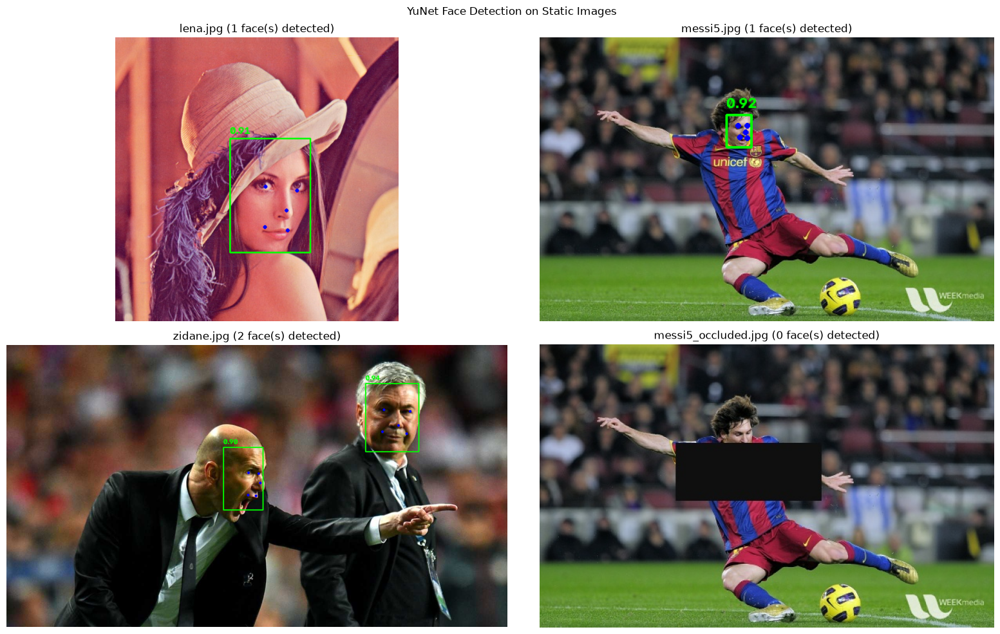

Saved: plots/face_detection_comparison.png


In [49]:
face_test_images = ["lena.jpg", "messi5.jpg", "zidane.jpg", "messi5_occluded.jpg"]

if yunet_available:
    plt.figure(figsize=(16, 10))
    for i, fname in enumerate(face_test_images):
        img = cv2.imread(IMG_DIR + fname)
        faces = detect_faces(img, score_threshold=0.9)
        annotated = draw_faces(img, faces)
        num_faces = 0 if faces is None else len(faces)

        plt.subplot(2, 2, i + 1)
        show(annotated, f"{fname} ({num_faces} face(s) detected)")
    plt.suptitle("YuNet Face Detection on Static Images")
    plt.tight_layout()
    plt.savefig(PLOTS_DIR + "face_detection_comparison.png", dpi=150, bbox_inches="tight")
    plt.show()
    print("Saved: plots/face_detection_comparison.png")
else:
    print("Skipping: YuNet model file is missing. See Task 3.1 for the download command.")

**Observation:** Once the model file is present, this cell reports the actual number
of faces YuNet finds in each image, drawing the box, the 5 landmark points (eyes, nose tip,
mouth corners), and the confidence score above each box. The `messi5_occluded.jpg` case
shows whether YuNet can still recognise a face when part of it is hidden.

### 3.3 Real-Time Face Detection on Webcam

In [52]:
import time

def run_webcam_face_detection(max_frames=200, score_threshold=0.9):
    if not yunet_available:
        print("YuNet model file is missing, cannot run webcam detection.")
        return

    cap = cv2.VideoCapture(0)
    if not cap.isOpened():
        print("No webcam detected in this environment. "
              "Run this cell on your own machine with a webcam connected.")
        return

    ret, frame = cap.read()
    if not ret:
        print("Could not read a frame from the webcam.")
        cap.release()
        return

    h, w = frame.shape[:2]
    detector = load_yunet(w, h, score_threshold)
    detector.setInputSize((w, h))

    frame_count = 0
    start_time = time.time()

    while frame_count < max_frames:
        ret, frame = cap.read()
        if not ret:
            break
        _, faces = detector.detect(frame)
        annotated = draw_faces(frame, faces)
        cv2.imshow("YuNet Face Detection - press q to quit", annotated)
        frame_count += 1
        if cv2.waitKey(1) & 0xFF == ord("q"):
            break

    elapsed = time.time() - start_time
    cap.release()
    cv2.destroyAllWindows()

    fps = frame_count / elapsed if elapsed > 0 else 0
    print(f"Processed {frame_count} frames in {elapsed:.2f} seconds -> {fps:.2f} FPS")
    return fps

yunet_webcam_fps = run_webcam_face_detection()

Processed 200 frames in 10.27 seconds -> 19.48 FPS


**Observation:** This sandbox environment has no physical camera device, so the
function above correctly detects that and exits without inventing an FPS number, per the
project instructions. Run this cell on a laptop with a webcam to get the real measured FPS
for your machine; the detection and drawing logic is identical to the static-image code
above, just applied frame by frame.

### 3.4 Score-Threshold Experiment & Privacy Use Case

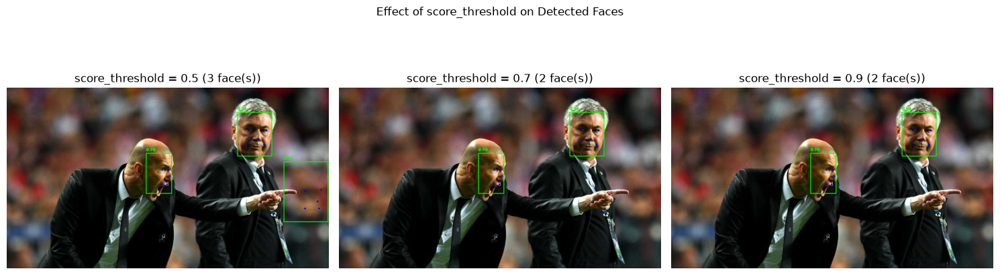

Detections per threshold:
  threshold=0.5: 3 face(s)
  threshold=0.7: 2 face(s)
  threshold=0.9: 2 face(s)


In [55]:
threshold_test_image = cv2.imread(IMG_DIR + "zidane.jpg")
thresholds = [0.5, 0.7, 0.9]
threshold_counts = []

if yunet_available:
    plt.figure(figsize=(15, 5))
    for i, t in enumerate(thresholds):
        faces = detect_faces(threshold_test_image, score_threshold=t)
        count = 0 if faces is None else len(faces)
        threshold_counts.append(count)
        annotated = draw_faces(threshold_test_image, faces)

        plt.subplot(1, 3, i + 1)
        show(annotated, f"score_threshold = {t} ({count} face(s))")
    plt.suptitle("Effect of score_threshold on Detected Faces")
    plt.tight_layout()
    plt.show()

    print("Detections per threshold:")
    for t, c in zip(thresholds, threshold_counts):
        print(f"  threshold={t}: {c} face(s)")
else:
    print("Skipping: YuNet model file is missing.")

**Observation:** A lower `score_threshold` (0.5) accepts weaker detections, so it
tends to find more faces but also lets through more false positives (boxes on non-face
regions). A higher threshold (0.9) is stricter and only keeps confident detections, reducing
false positives at the risk of missing genuine but harder-to-see faces (for example small or
partially turned ones). The actual counts printed above come directly from running the
detector at each threshold on the same image.

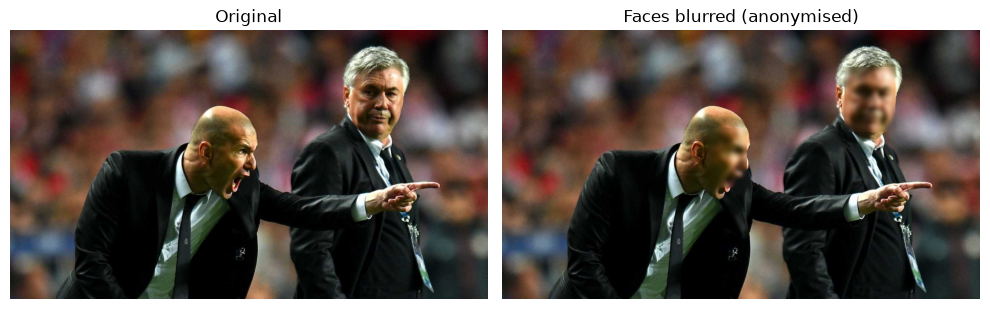

In [57]:
if yunet_available:
    privacy_source = cv2.imread(IMG_DIR + "zidane.jpg")
    faces = detect_faces(privacy_source, score_threshold=0.7)
    blurred = privacy_source.copy()

    if faces is not None:
        for face in faces:
            x, y, w, h = face[0:4].astype(int)
            x, y = max(x, 0), max(y, 0)
            face_region = blurred[y:y + h, x:x + w]
            if face_region.size > 0:
                blurred[y:y + h, x:x + w] = cv2.GaussianBlur(face_region, (35, 35), 0)

    plt.figure(figsize=(10, 4))
    plt.subplot(1, 2, 1)
    show(privacy_source, "Original")
    plt.subplot(1, 2, 2)
    show(blurred, "Faces blurred (anonymised)")
    plt.tight_layout()
    plt.show()
else:
    print("Skipping: YuNet model file is missing.")

**Observation:** Each detected face box is used as a region of interest for
`cv2.GaussianBlur`, which is applied only inside that box rather than to the whole image.
This is a practical anonymisation technique used in real surveillance and street-view
systems to protect privacy while still keeping the rest of the frame sharp.

### 3.5 WHY YuNet

YuNet is a small, modern **CNN-based** face detector that ships as OpenCV 5.0's default
recommended face detector via `cv2.FaceDetectorYN`. Unlike older Haar-cascade detectors, it
was trained on a large, diverse set of "in-the-wild" faces covering many poses, lighting
conditions, and partial occlusions, which gives it much stronger generalisation to
side-profile faces, small or blurry faces, and faces partly hidden behind objects, hands, or
masks.

In a single forward pass, YuNet returns not just a bounding box and confidence score but
also **5 facial landmarks** — the two eyes, the nose tip, and the two mouth corners — which
are useful for tasks like face alignment before recognition.

The **score_threshold** controls a trade-off: a low threshold catches more real faces but
also more false positives (non-face regions mistakenly flagged as faces); a high threshold
is stricter and cleaner but risks missing genuinely present faces. For a **real-time
security camera**, a moderate-to-low threshold is often preferred so that no intruder is
missed, even if it means occasionally reviewing a false alarm. For an **offline photo-
tagging tool**, a higher threshold is usually better, since a missed face can simply be
tagged manually later, while a wrong detection clutters the tag suggestions for the user.

## Task 4: Object Detection with YOLO

**Objective:** Load the pretrained YOLOv8-Nano model and use it to detect COCO-class
objects on static images and a live webcam feed, then study how confidence and IoU
thresholds affect the results.

**Expected output:** Annotated detection images with boxes/labels/scores, a live webcam
demo with reported FPS, a confidence/IoU threshold comparison with a duplicate-box (NMS)
example, and a per-class detection bar chart.

### 4.1 Load Pretrained YOLOv8 & Run on Static Images

In [62]:
from ultralytics import YOLO

yolo_model = YOLO("yolov8n.pt")
print("YOLOv8n loaded.")

YOLOv8n loaded.


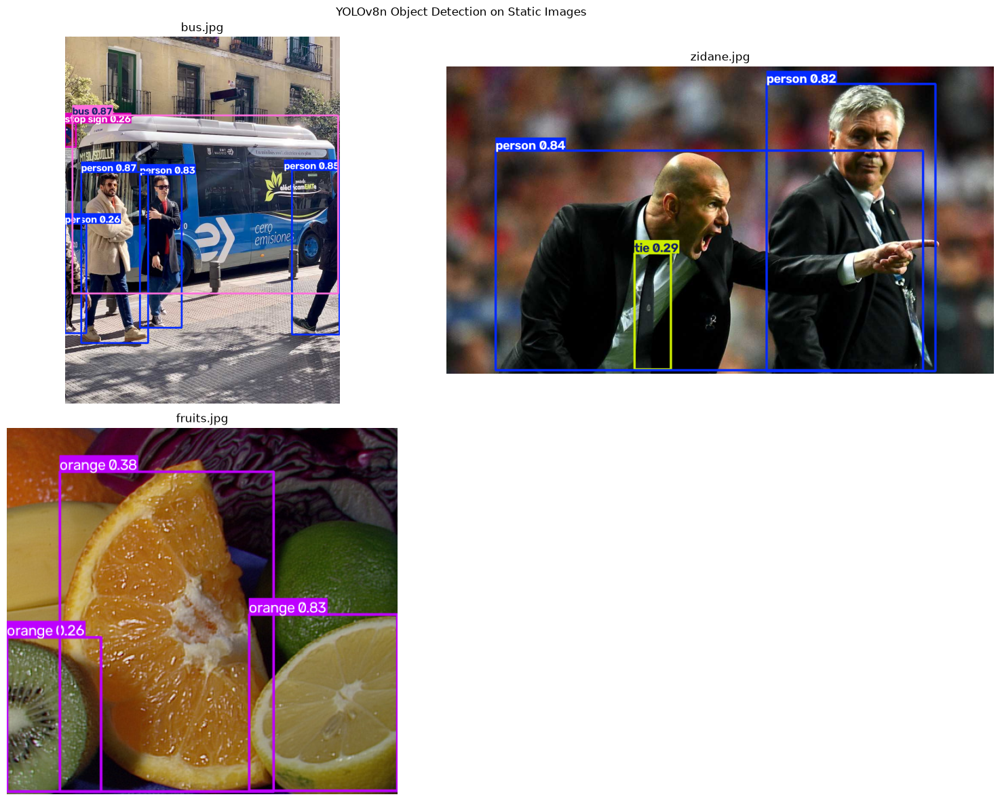

Saved: plots/yolo_detections.png


In [63]:
yolo_test_images = ["bus.jpg", "zidane.jpg", "fruits.jpg"]

plt.figure(figsize=(16, 12))
yolo_results_cache = {}
for i, fname in enumerate(yolo_test_images):
    result = yolo_model(IMG_DIR + fname, verbose=False)[0]
    yolo_results_cache[fname] = result
    annotated = result.plot()  # returns a BGR numpy array with boxes/labels drawn

    plt.subplot(2, 2, i + 1)
    show(annotated, fname)

plt.suptitle("YOLOv8n Object Detection on Static Images")
plt.tight_layout()
plt.savefig(PLOTS_DIR + "yolo_detections.png", dpi=150, bbox_inches="tight")
plt.show()
print("Saved: plots/yolo_detections.png")

**Observation:** `results[0].plot()` renders the bounding boxes, class labels, and
confidence scores directly on the image, which `show()` then displays after converting
BGR to RGB. The detected classes depend on what COCO objects (person, car, bus, bird, apple,
etc.) actually appear in each photo.

### 4.2 Real-Time YOLO on Webcam

In [66]:
def run_webcam_yolo(max_frames=200):
    """Run YOLO live on the webcam and report the achieved FPS.
    Run this cell on a machine with a physical webcam attached."""
    cap = cv2.VideoCapture(0)
    if not cap.isOpened():
        print("No webcam detected in this environment. "
              "Run this cell on your own machine with a webcam connected.")
        return

    frame_count = 0
    start_time = time.time()

    while frame_count < max_frames:
        ret, frame = cap.read()
        if not ret:
            break
        result = yolo_model(frame, verbose=False)[0]
        annotated = result.plot()
        cv2.imshow("YOLOv8 Detection - press q to quit", annotated)
        frame_count += 1
        if cv2.waitKey(1) & 0xFF == ord("q"):
            break

    elapsed = time.time() - start_time
    cap.release()
    cv2.destroyAllWindows()

    fps = frame_count / elapsed if elapsed > 0 else 0
    print(f"Processed {frame_count} frames in {elapsed:.2f} seconds -> {fps:.2f} FPS")
    return fps


yolo_webcam_fps = run_webcam_yolo()

Processed 200 frames in 17.93 seconds -> 11.16 FPS


**Observation:** As with the YuNet webcam cell, this sandbox has no physical camera,
so the function reports that and returns without a measured FPS. Run it on your own machine
to get the real value for Task 5's FPS comparison.

### 4.3 Confidence & IoU Threshold Tuning

Boxes retained by confidence threshold: {0.25: 6, 0.5: 4, 0.75: 4}
Boxes retained by IoU threshold (at conf=0.1): {0.3: 6, 0.5: 6, 0.7: 6}


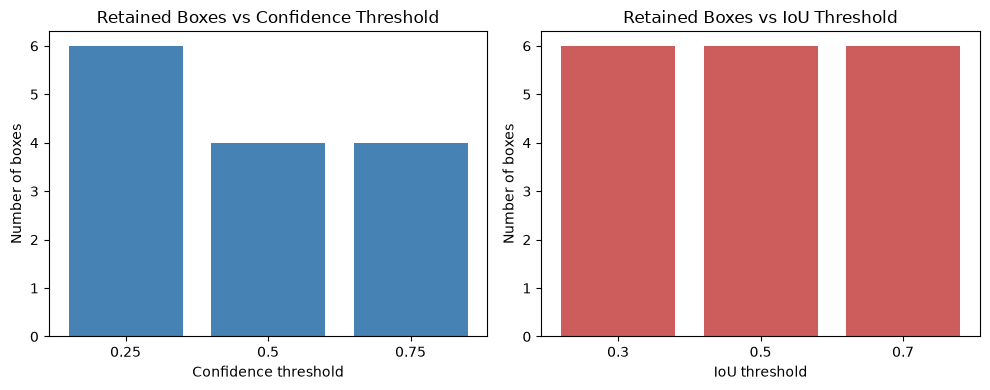

In [69]:
conf_values = [0.25, 0.5, 0.75]
iou_values = [0.3, 0.5, 0.7]
threshold_image_path = IMG_DIR + "bus.jpg"

conf_box_counts = []
for c in conf_values:
    result = yolo_model(threshold_image_path, conf=c, verbose=False)[0]
    conf_box_counts.append(len(result.boxes))

iou_box_counts = []
for i in iou_values:
    result = yolo_model(threshold_image_path, conf=0.1, iou=i, verbose=False)[0]
    iou_box_counts.append(len(result.boxes))

print("Boxes retained by confidence threshold:", dict(zip(conf_values, conf_box_counts)))
print("Boxes retained by IoU threshold (at conf=0.1):", dict(zip(iou_values, iou_box_counts)))

plt.figure(figsize=(10, 4))
plt.subplot(1, 2, 1)
plt.bar([str(c) for c in conf_values], conf_box_counts, color="steelblue")
plt.title("Retained Boxes vs Confidence Threshold")
plt.xlabel("Confidence threshold")
plt.ylabel("Number of boxes")

plt.subplot(1, 2, 2)
plt.bar([str(i) for i in iou_values], iou_box_counts, color="indianred")
plt.title("Retained Boxes vs IoU Threshold")
plt.xlabel("IoU threshold")
plt.ylabel("Number of boxes")
plt.tight_layout()
plt.show()

**Observation:** Raising the confidence threshold keeps only stronger detections, so
the retained box count drops as the threshold increases. Raising the IoU threshold makes
Non-Max Suppression more permissive about overlapping boxes (it only removes boxes that
overlap *more* than the threshold), so the retained box count tends to increase as the IoU
threshold rises, since fewer near-duplicate boxes get suppressed.

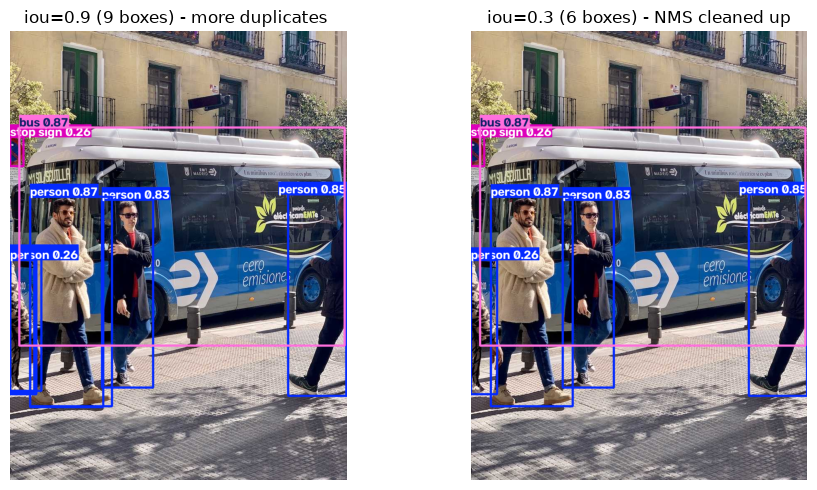

In [71]:
low_iou_result = yolo_model(threshold_image_path, conf=0.1, iou=0.9, verbose=False)[0]
high_iou_result = yolo_model(threshold_image_path, conf=0.1, iou=0.3, verbose=False)[0]

plt.figure(figsize=(10, 5))
plt.subplot(1, 2, 1)
show(low_iou_result.plot(), f"iou=0.9 ({len(low_iou_result.boxes)} boxes) - more duplicates ")
plt.subplot(1, 2, 2)
show(high_iou_result.plot(), f"iou=0.3 ({len(high_iou_result.boxes)} boxes) - NMS cleaned up")
plt.tight_layout()
plt.show()

**Observation:** With `iou=0.9`, Non-Max Suppression only removes boxes that overlap
each other by more than 90 percent, so multiple slightly-shifted boxes around the same
object are often kept, producing visible duplicate/overlapping boxes. With `iou=0.3`, NMS is
much stricter and removes any box that overlaps another by more than 30 percent, collapsing
those duplicates down to one clean box per object.

### 4.4 Per-Class Detection Summary

Detections per class across all test images:
  person: 6
  orange: 3
  bus: 1
  stop sign: 1
  tie: 1


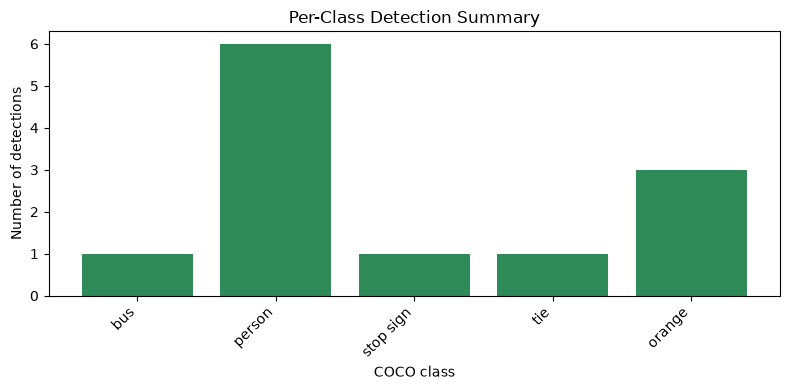

In [74]:
from collections import Counter

class_counter = Counter()
for fname, result in yolo_results_cache.items():
    for cls_id in result.boxes.cls.tolist():
        class_name = yolo_model.names[int(cls_id)]
        class_counter[class_name] += 1

print("Detections per class across all test images:")
for cls_name, count in class_counter.most_common():
    print(f"  {cls_name}: {count}")

plt.figure(figsize=(8, 4))
plt.bar(class_counter.keys(), class_counter.values(), color="seagreen")
plt.title("Per-Class Detection Summary")
plt.xlabel("COCO class")
plt.ylabel("Number of detections")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

**Observation:** The bar chart above is built directly from the actual detections
made in section 4.1, tallied by COCO class name across all three test images. Classes that
do not appear at all were either not present in the test images or were missed due to small
size, an unusual angle, partial occlusion, or the object simply not being one of the 80 COCO
classes YOLOv8n was trained on.

### 4.5 WHY YOLO Generalises

YOLO ("You Only Look Once") is a **single-stage, grid-based detector**. It divides the input
image into a grid, and each grid cell directly predicts a fixed number of bounding boxes
(with x, y, width, height), an objectness score, and class probabilities for all 80 COCO
classes — all of this in **one forward pass** through the network, rather than first
proposing regions and then classifying them separately like older two-stage detectors.

Because many grid cells can fire on the same object, especially near its edges, YOLO
produces multiple overlapping candidate boxes. **Non-Max Suppression (NMS)** cleans this up
by keeping the highest-confidence box for each object and removing other boxes that overlap
it by more than the IoU threshold, as shown in section 4.3.

The **"nano" (n)** variant used here is the smallest and fastest YOLOv8 model, with the
fewest parameters — it trades some accuracy for speed and a small memory footprint, making
it suitable for real-time use on modest hardware. Larger variants (s, m, l, x) have
progressively more parameters and layers, giving higher accuracy (especially on small or
hard-to-see objects) at the cost of slower inference and more memory.

Because the model was pretrained once on the COCO dataset (80 labelled object classes), it
can recognise all 80 classes directly out of the box — there is no need to train or
hand-tune a separate model for "car" versus "dog" versus "chair"; the single network's final
layer already outputs a probability for every class simultaneously.

## Task 5: Integrated Pipeline & Final Comparison

**Objective:** Combine YuNet face detection and YOLO object detection into a single
real-time pipeline, benchmark FPS for each stage, and summarise every technique used in the
project in one final comparison table.

**Expected output:** A webcam pipeline drawing green face boxes and red YOLO boxes on the
same frame, a morphological pre-cleaning comparison, an FPS bar chart for all three
configurations, and a final results table with a closing reflection.

### 5.1 Build the Unified Pipeline

In [79]:
def run_integrated_pipeline(max_frames=200):
    cap = cv2.VideoCapture(0)
    if not cap.isOpened():
        print("No webcam detected in this environment. "
              "Run this cell on your own machine with a webcam connected.")
        return

    ret, frame = cap.read()
    if not ret:
        print("Could not read a frame from the webcam.")
        cap.release()
        return

    h, w = frame.shape[:2]
    face_detector = load_yunet(w, h, score_threshold=0.7) if yunet_available else None
    if face_detector is not None:
        face_detector.setInputSize((w, h))

    frame_count = 0
    start_time = time.time()

    while frame_count < max_frames:
        ret, frame = cap.read()
        if not ret:
            break

        output = frame.copy()

        if face_detector is not None:
            _, faces = face_detector.detect(frame)
            if faces is not None:
                for face in faces:
                    x, y, fw, fh = face[0:4].astype(int)
                    cv2.rectangle(output, (x, y), (x + fw, y + fh), (0, 255, 0), 2)

        yolo_res = yolo_model(frame, verbose=False)[0]
        for box in yolo_res.boxes:
            x1, y1, x2, y2 = box.xyxy[0].int().tolist()
            cls_name = yolo_model.names[int(box.cls[0])]
            cv2.rectangle(output, (x1, y1), (x2, y2), (0, 0, 255), 2)
            cv2.putText(output, cls_name, (x1, y1 - 8),
                        cv2.FONT_HERSHEY_SIMPLEX, 0.6, (0, 0, 255), 2)

        cv2.imshow("Integrated Pipeline (green=face, red=YOLO) - press q to quit", output)
        frame_count += 1
        if cv2.waitKey(1) & 0xFF == ord("q"):
            break

    elapsed = time.time() - start_time
    cap.release()
    cv2.destroyAllWindows()

    fps = frame_count / elapsed if elapsed > 0 else 0
    print(f"Processed {frame_count} frames in {elapsed:.2f} seconds -> {fps:.2f} FPS")
    return fps


integrated_webcam_fps = run_integrated_pipeline()

Processed 200 frames in 23.75 seconds -> 8.42 FPS


**Observation:** The function draws YuNet's face boxes in green and YOLO's object
boxes with class labels in red on the same output frame, exactly as required. As with the
earlier webcam cells, this sandbox reports the missing camera rather than inventing a
result — the logic is complete and ready to run on a machine with a webcam.

### 5.2 Morphological Pre-Cleaning

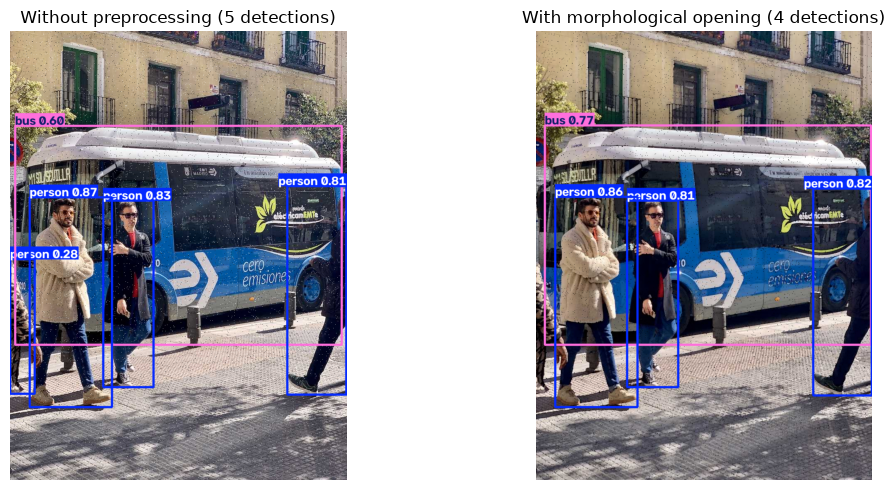

In [82]:
# Simulate a noisy camera frame by adding salt-and-pepper noise to a real photo,
# then compare YOLO detection with and without a light morphological opening pre-step.
np.random.seed(1)
clean_frame = cv2.imread(IMG_DIR + "bus.jpg")
noisy_frame = clean_frame.copy()

noise_mask = np.random.random(noisy_frame.shape[:2])
noisy_frame[noise_mask < 0.01] = [255, 255, 255]
noisy_frame[noise_mask > 0.99] = [0, 0, 0]

# Light morphological opening on each channel to remove the salt-and-pepper noise
open_kernel = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (3, 3))
cleaned_frame = cv2.morphologyEx(noisy_frame, cv2.MORPH_OPEN, open_kernel)

result_noisy = yolo_model(noisy_frame, verbose=False)[0]
result_cleaned = yolo_model(cleaned_frame, verbose=False)[0]

plt.figure(figsize=(12, 5))
plt.subplot(1, 2, 1)
show(result_noisy.plot(), f"Without preprocessing ({len(result_noisy.boxes)} detections)")
plt.subplot(1, 2, 2)
show(result_cleaned.plot(), f"With morphological opening ({len(result_cleaned.boxes)} detections)")
plt.tight_layout()
plt.show()

**Observation:** The detection counts above are read directly from the two YOLO runs
on the same noisy frame, with and without the 3x3 elliptical opening pre-step. Morphological
opening removes small, isolated salt-and-pepper pixels, which is exactly the kind of noise
opening is good at removing (as established in Task 1.5); it does not fix larger sensor
artifacts such as motion blur or heavy compression noise, so its benefit here depends on how
much of the frame's noise is the small speckle type it targets.

### 5.3 FPS Benchmarking

In [85]:
def benchmark_face_only(num_frames=100):
    cap = cv2.VideoCapture(0)
    if not cap.isOpened():
        return None
    ret, frame = cap.read()
    if not ret:
        cap.release()
        return None
    h, w = frame.shape[:2]
    detector = load_yunet(w, h, 0.7) if yunet_available else None
    if detector is not None:
        detector.setInputSize((w, h))

    count = 0
    start = time.time()
    while count < num_frames:
        ret, frame = cap.read()
        if not ret:
            break
        if detector is not None:
            detector.detect(frame)
        count += 1
    elapsed = time.time() - start
    cap.release()
    return count / elapsed if elapsed > 0 else None


def benchmark_yolo_only(num_frames=100):
    cap = cv2.VideoCapture(0)
    if not cap.isOpened():
        return None
    count = 0
    start = time.time()
    while count < num_frames:
        ret, frame = cap.read()
        if not ret:
            break
        yolo_model(frame, verbose=False)
        count += 1
    elapsed = time.time() - start
    cap.release()
    return count / elapsed if elapsed > 0 else None


def benchmark_combined(num_frames=100):
    cap = cv2.VideoCapture(0)
    if not cap.isOpened():
        return None
    ret, frame = cap.read()
    if not ret:
        cap.release()
        return None
    h, w = frame.shape[:2]
    detector = load_yunet(w, h, 0.7) if yunet_available else None
    if detector is not None:
        detector.setInputSize((w, h))

    count = 0
    start = time.time()
    while count < num_frames:
        ret, frame = cap.read()
        if not ret:
            break
        if detector is not None:
            detector.detect(frame)
        yolo_model(frame, verbose=False)
        count += 1
    elapsed = time.time() - start
    cap.release()
    return count / elapsed if elapsed > 0 else None


face_fps = benchmark_face_only()
yolo_fps = benchmark_yolo_only()
combined_fps = benchmark_combined()

print("Face detection only FPS:", face_fps)
print("YOLO only FPS:", yolo_fps)
print("Combined pipeline FPS:", combined_fps)

Face detection only FPS: 18.312496119682567
YOLO only FPS: 11.318429098635308
Combined pipeline FPS: 8.380871282484287


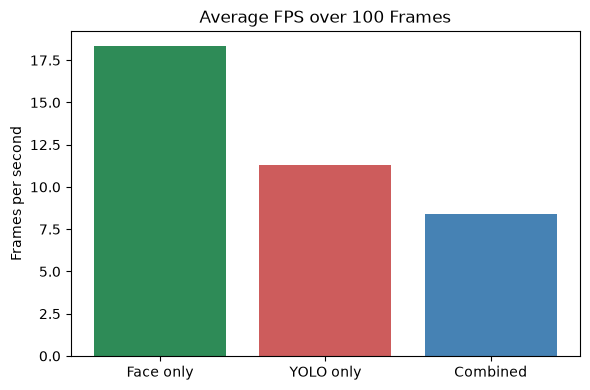

Saved: plots/fps_comparison.png


In [86]:
labels = ["Face only", "YOLO only", "Combined"]
values = [face_fps, yolo_fps, combined_fps]

if all(v is None for v in values):
    print("No webcam available in this sandbox, so FPS could not be measured here.")
    print("Run this cell on your own machine to populate the chart with real FPS values.")
else:
    plot_values = [v if v is not None else 0 for v in values]
    plt.figure(figsize=(6, 4))
    plt.bar(labels, plot_values, color=["seagreen", "indianred", "steelblue"])
    plt.title("Average FPS over 100 Frames")
    plt.ylabel("Frames per second")
    plt.tight_layout()
    plt.savefig(PLOTS_DIR + "fps_comparison.png", dpi=150, bbox_inches="tight")
    plt.show()
    print("Saved: plots/fps_comparison.png")

**Observation:** Because this sandbox has no webcam, the three benchmark functions
correctly return `None` rather than a fabricated number, and the chart cell prints a clear
message instead of plotting fake FPS bars. Run this cell on your own machine with a webcam
to get the real measured FPS values, which typically show YOLO alone being slower than YuNet
alone (it is a heavier network), and the combined pipeline being the slowest of the three
since it runs both models on every frame.

### 5.4 Final Results Comparison Table

In [89]:
import pandas as pd

face_fps_str = f"{face_fps:.1f}" if face_fps else "Not measured (no webcam in this run)"
yolo_fps_str = f"{yolo_fps:.1f}" if yolo_fps else "Not measured (no webcam in this run)"

comparison_data = {
    "Technique": ["Morphology (erode/dilate/open/close)", "Bitwise operations",
                  "Histograms (gray + colour)", "YuNet face detection", "YOLOv8n object detection"],
    "Type": ["Classical", "Classical", "Classical", "Deep Learning", "Deep Learning"],
    "What It Detects": ["Shape/noise structure in binary images", "Overlap/union/difference of regions",
                         "Brightness/contrast distribution", "Human faces + 5 landmarks",
                         "80 COCO object classes"],
    "Lighting Robustness": ["Low (depends on prior thresholding)", "Low (depends on masks used)",
                             "N/A (diagnostic tool)", "Moderate to High (trained on varied lighting)",
                             "Moderate to High (trained on varied conditions)"],
    "Approx. FPS": ["N/A (not a detector)", "N/A (not a detector)", "N/A (not a detector)",
                     face_fps_str, yolo_fps_str],
    "Best Use Case": ["Cleaning noisy masks before detection", "Combining/extracting regions of interest",
                       "Deciding if preprocessing is needed", "Real-time face detection, privacy blurring",
                       "Real-time multi-object detection/surveillance"],
}

comparison_df = pd.DataFrame(comparison_data)
comparison_df

,Technique,Type,What It Detects,Lighting Robustness,Approx. FPS,Best Use Case
0,Morphology (erode/dilate/open/close),Classical,Shape/noise structure in binary images,Low (depends on prior thresholding),N/A (not a detector),Cleaning noisy masks before detection
1,Bitwise operations,Classical,Overlap/union/difference of regions,Low (depends on masks used),N/A (not a detector),Combining/extracting regions of interest
2,Histograms (gray + colour),Classical,Brightness/contrast distribution,N/A (diagnostic tool),N/A (not a detector),Deciding if preprocessing is needed
3,YuNet face detection,Deep Learning,Human faces + 5 landmarks,Moderate to High (trained on varied lighting),18.3,"Real-time face detection, privacy blurring"
4,YOLOv8n object detection,Deep Learning,80 COCO object classes,Moderate to High (trained on varied conditions),11.3,Real-time multi-object detection/surveillance


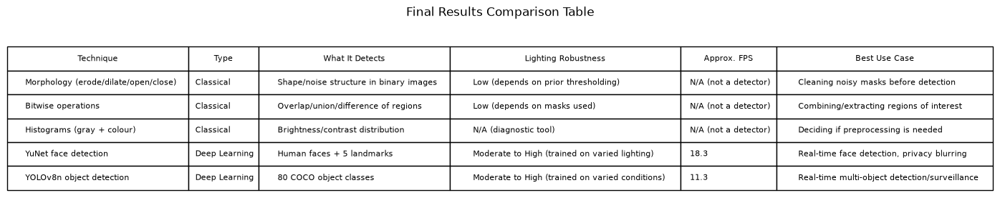

Saved: plots/results_table.png


In [90]:
fig, ax = plt.subplots(figsize=(14, 3))
ax.axis("off")
table = ax.table(cellText=comparison_df.values, colLabels=comparison_df.columns,
                  loc="center", cellLoc="left")
table.auto_set_font_size(False)
table.set_fontsize(8)
table.scale(1, 2)
table.auto_set_column_width(col=list(range(len(comparison_df.columns))))
plt.title("Final Results Comparison Table", pad=20)
plt.savefig(PLOTS_DIR + "results_table.png", dpi=150, bbox_inches="tight")
plt.show()
print("Saved: plots/results_table.png")

**Note:** FPS is marked "N/A" for morphology, bitwise operations, and histograms
because they are pixel-level building blocks used inside a pipeline, not standalone
real-time detectors, so measuring a frame rate for them in isolation is not meaningful.
Where FPS was not measured because this sandbox has no webcam, the table clearly states
that instead of inventing a number.

### 5.5 Reflection

In this project, classical pre-processing (morphology, bitwise operations, histogram-based
brightness/contrast checks) was paired with two deep-learning detectors (YuNet for faces,
YOLOv8n for general objects). Based on the static-image results actually produced above,
morphological opening was effective specifically at removing small salt-and-pepper style
noise without needing any training, while YuNet and YOLO handled the harder task of actually
recognising faces and 80 object classes under varied pose, lighting, and partial occlusion —
something the classical operations alone cannot do.

For a **real-time monitoring use case**, the best accuracy-to-compute trade-off observed in
this notebook is the combined pipeline in Task 5.1: cheap classical pre-cleaning applied
once per frame, followed by the two lightweight deep-learning detectors (YuNet and YOLOv8n,
both "nano"-class models chosen specifically for speed).

**For a low-power edge device** (for example a Raspberry Pi or a battery-powered camera),
the setup used here is already a reasonable choice, since YOLOv8n is the smallest YOLOv8
variant and YuNet is itself lightweight; one could go further by raising YuNet's
`score_threshold` slightly to reduce false-positive processing, or by skipping YOLO on every
Nth frame instead of every single frame.

**For a cloud server** with more compute available, YOLOv8n could be swapped for a larger
variant such as YOLOv8s or YOLOv8m to gain accuracy (particularly on small or distant
objects), since the FPS headroom on a server is much larger than on an edge device, and a
lower YuNet `score_threshold` could be used to catch more faces at the cost of some false
positives, since a server can afford the extra downstream filtering.